<center><h1>Chen_Yanxiong_HW6</h1></center>

Name: Yanxiong Chen
<br>
Github Username: DevinChen02
<br>
USC ID: 2129850673

## 1. Tree-Based Methods

Import packages

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score, RocCurveDisplay
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import pymupdf
from IPython.display import Image, display

### (a) Download the APS Failure data

In [2]:
train = pd.read_csv("../data/aps_failure_training_set.csv", skiprows=20, na_values="na")
test = pd.read_csv("../data/aps_failure_test_set.csv", skiprows=20, na_values="na")
print(train.shape, test.shape)

(60000, 171) (16000, 171)


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Reference: https://scikit-learn.org/stable/modules/impute.html

To deal with data with missing values, common methods are replacing them with the mean/median/mode/a constant, or use KNN or regression to predict missing values. 

I choose to replace missing values with the mean of its feature because all predictors are numeric and the method is simple.

In [3]:
train = train.fillna(train.mean(numeric_only=True))
test = test.fillna(test.mean(numeric_only=True))

#### (ii) Calculate the coefficient of variation

In [4]:
cv = train.std(numeric_only=True) / train.mean(numeric_only=True)

#### (iii) Plot a correlation matrix

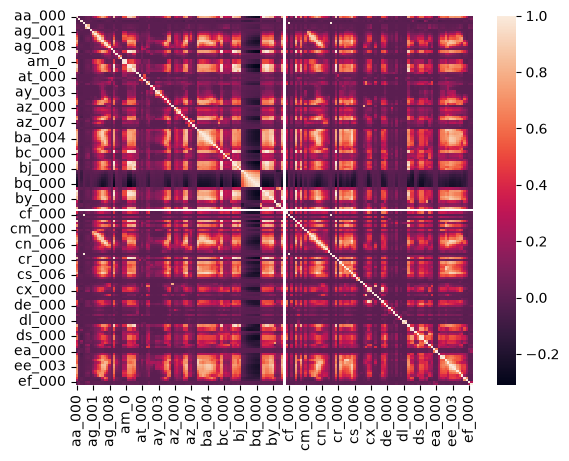

In [5]:
sns.heatmap(train.corr(numeric_only=True))
plt.show()

#### (iv) Make scatter plots and box plots

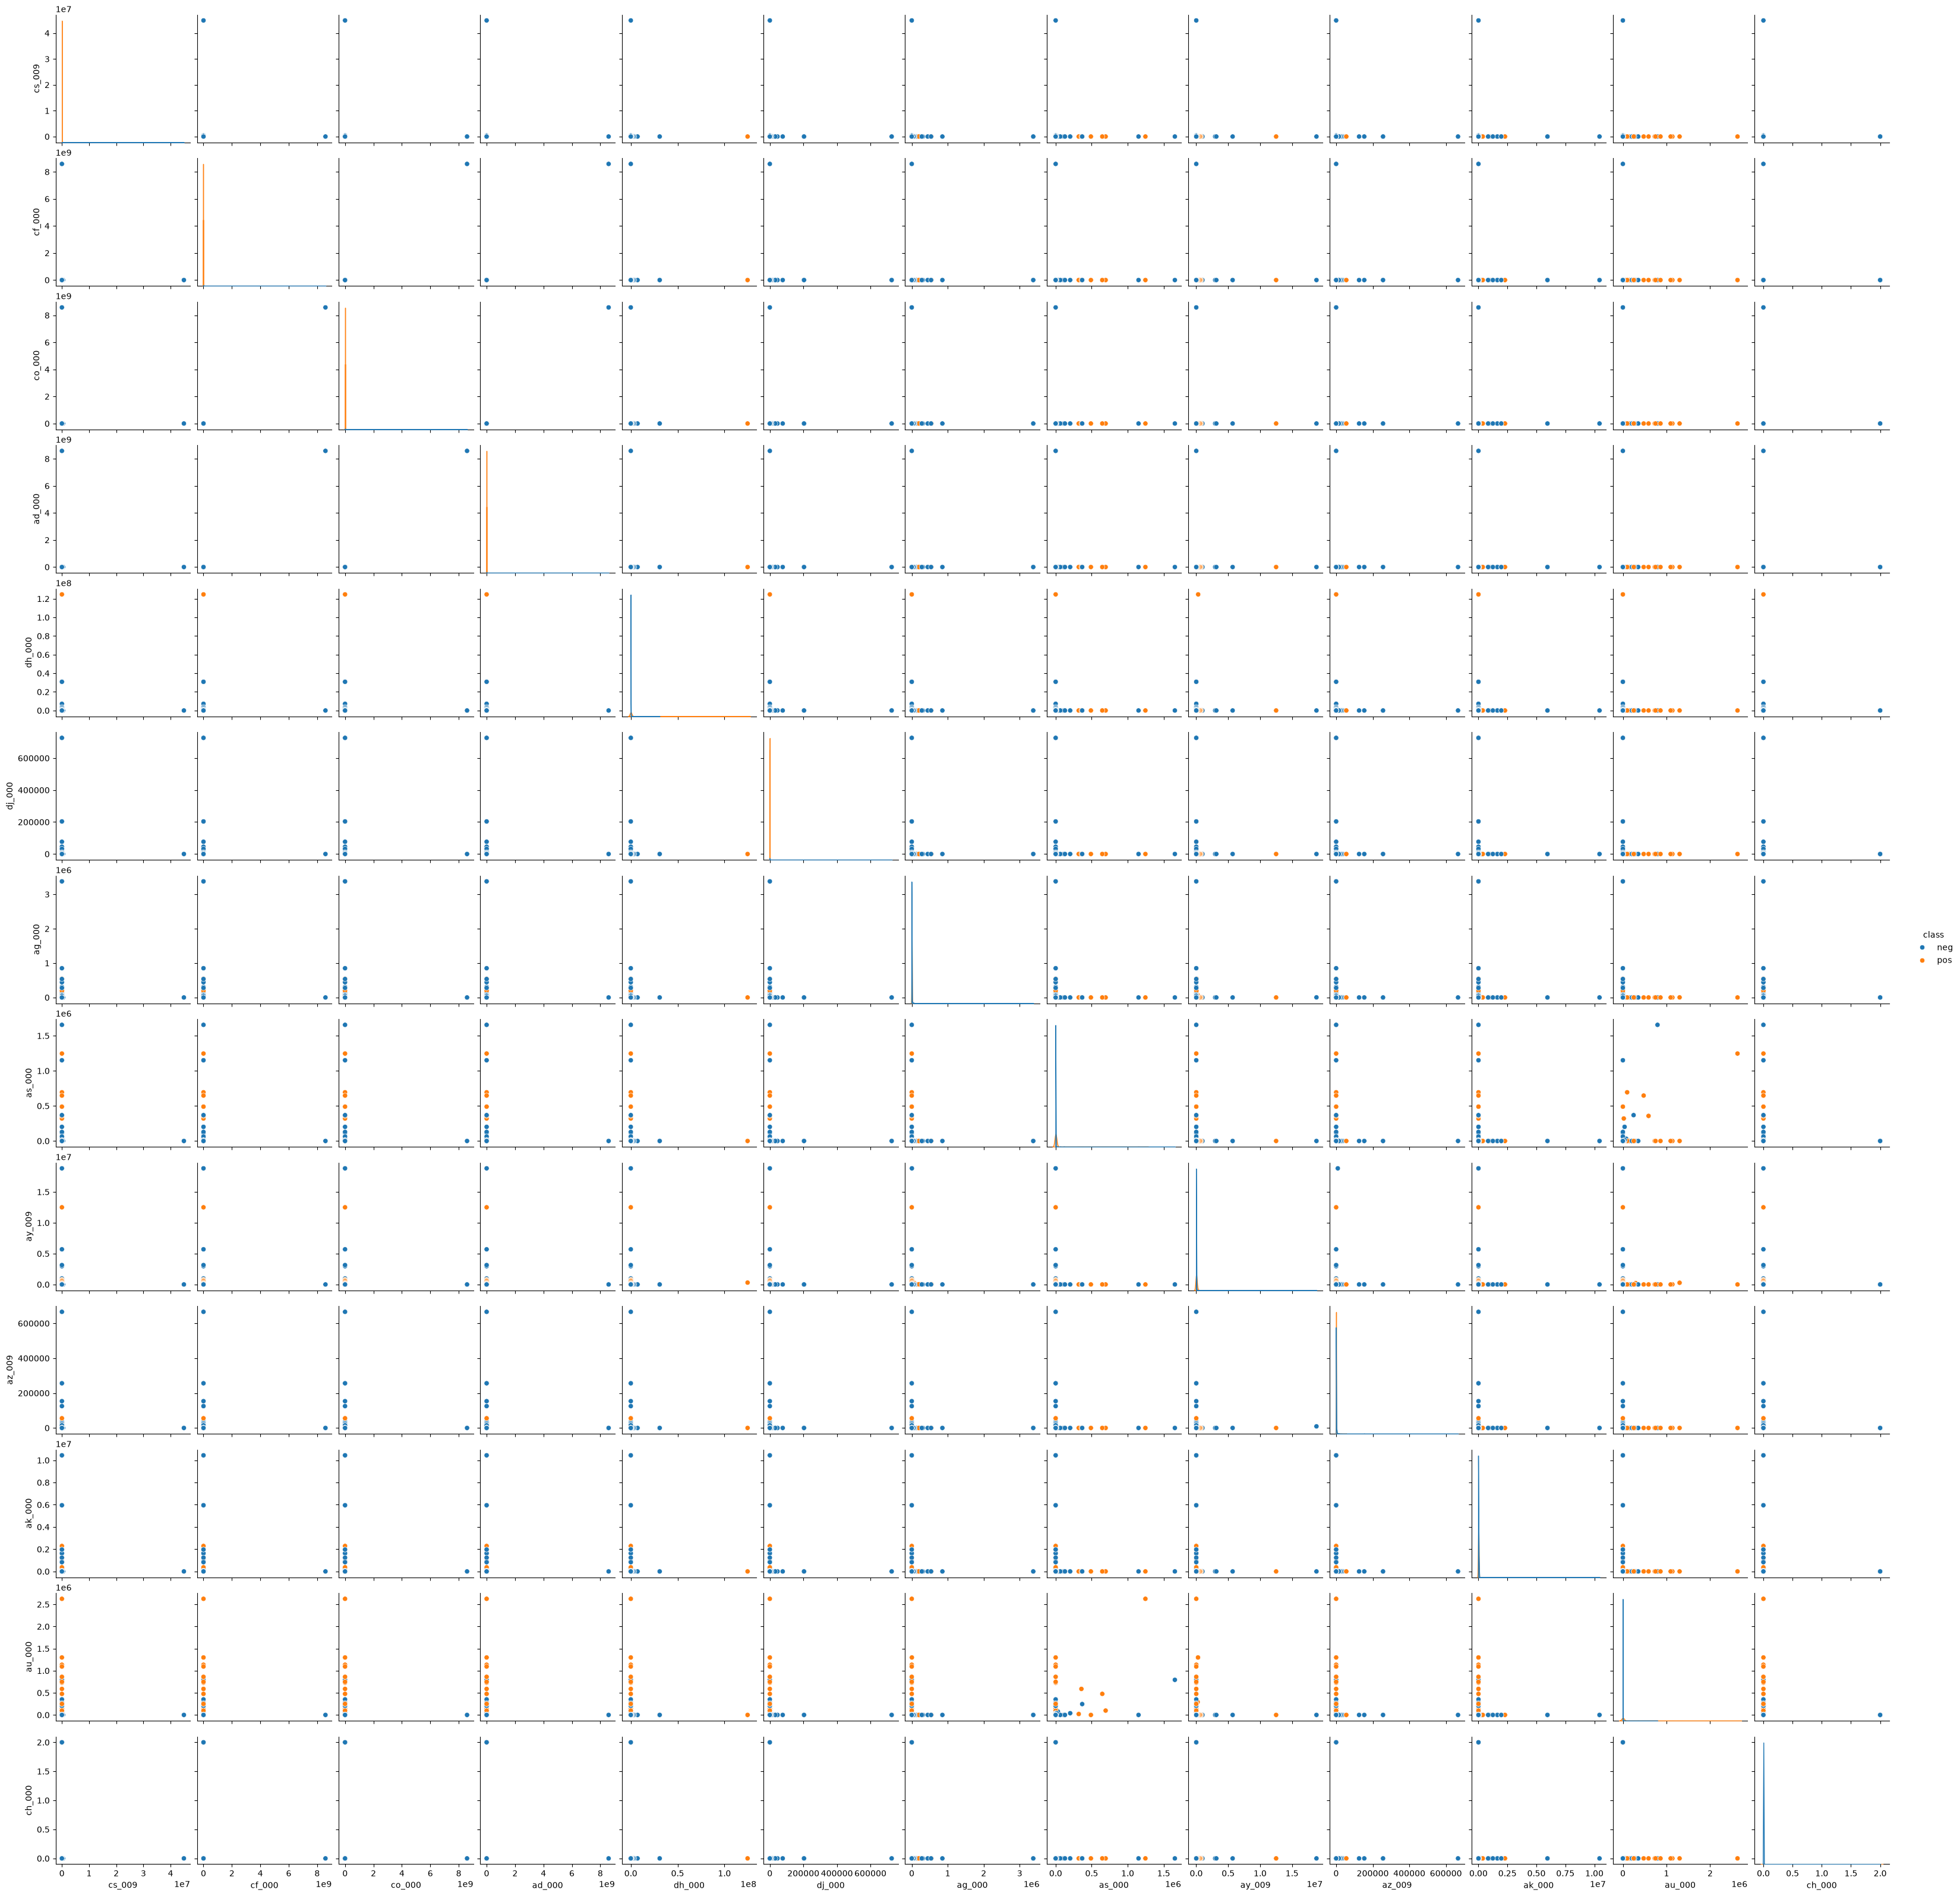

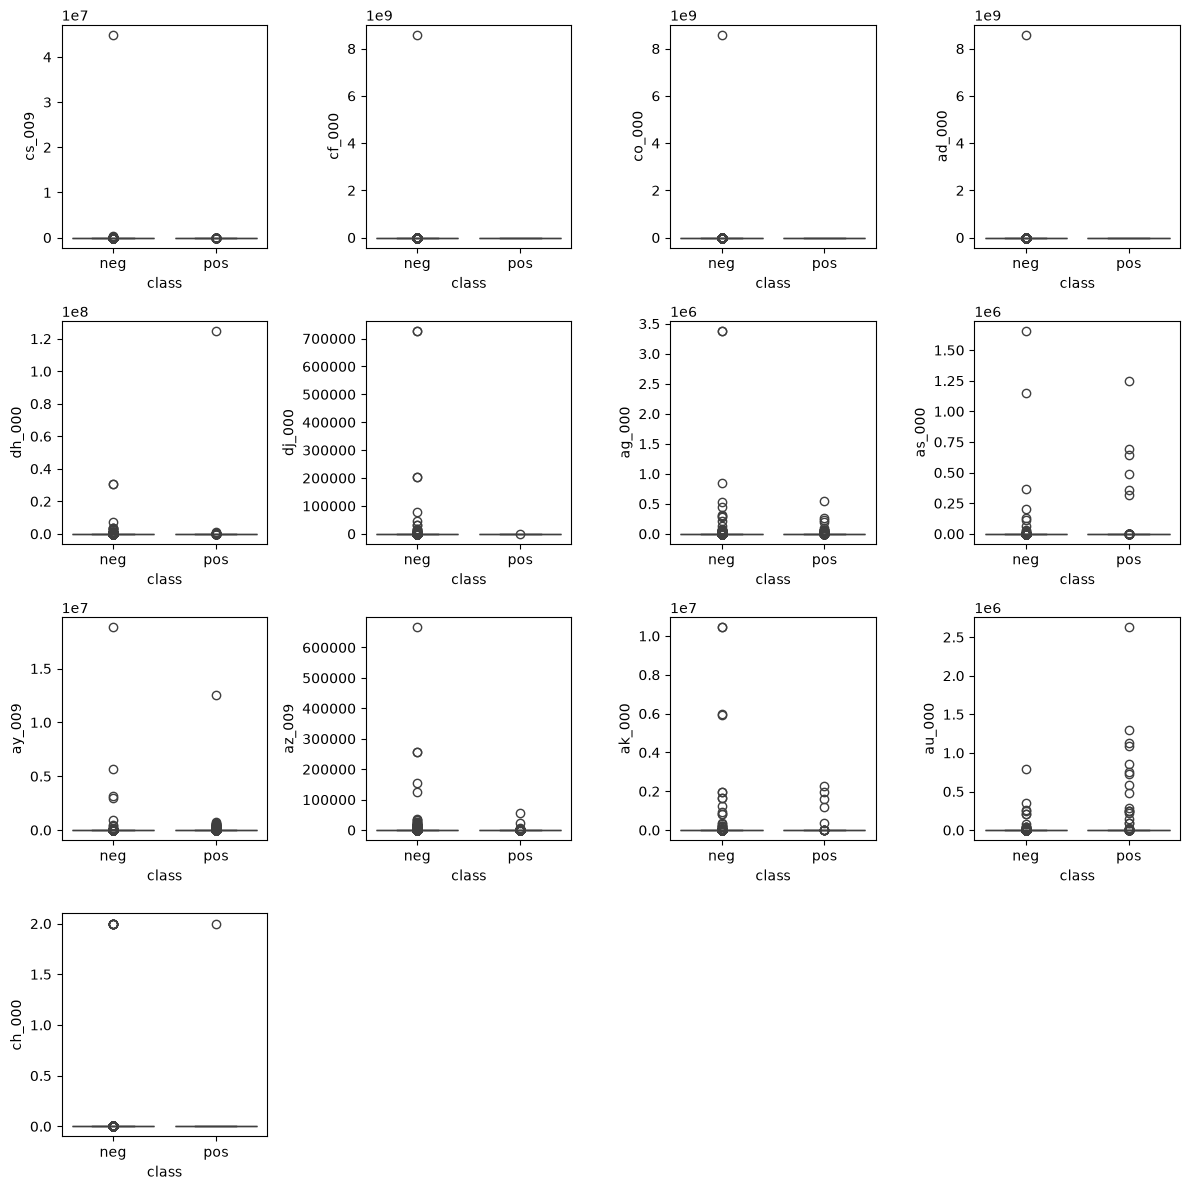

In [6]:
features = cv.nlargest(13).index
sns.pairplot(train, vars=features, hue="class")
plt.show()
plt.figure(figsize=(12, 12))
for i, feature in enumerate(features, 1):
    plt.subplot(4, 4, i)
    sns.boxplot(data=train, x="class", y=feature)
plt.tight_layout()
plt.show()

We can't draw conclusions about the significance of these features just by the scatter plots.

#### (v) Is this data set imbalanced?

In [7]:
print("Training:\n", train["class"].value_counts())
print("Test:\n", test["class"].value_counts())

Training:
 class
neg    59000
pos     1000
Name: count, dtype: int64
Test:
 class
neg    15625
pos      375
Name: count, dtype: int64


In training set, there are 59000 negative samples and 1000 positive samples. In the test set, there are 15625 negative samples and 375 positive samples. So the dataset is highly imbalanced. 

### (c) Train a random forest

Training
Confusion matrix:
 [[59000     0]
 [    0  1000]]
Misclassification rate: 0.0
AUC: 1.0
Test
Confusion matrix:
 [[15606    19]
 [   99   276]]
Misclassification rate: 0.007375
AUC: 0.993460224


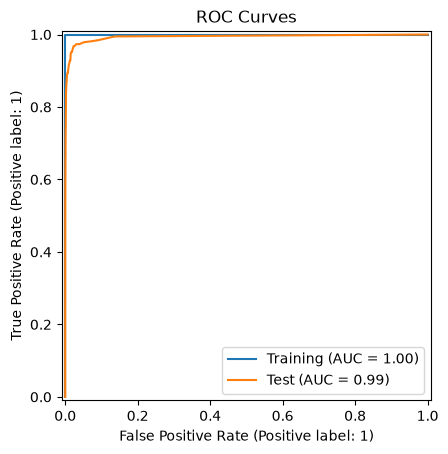

Out of Bag error: 0.00605
Test error: 0.00737500000000002
Out of Bag error - test error: -0.0013250000000000206


In [8]:
X_train = train.drop(columns="class")
y_train = train["class"].map({"neg": 0, "pos": 1})
X_test = test.drop(columns="class")
y_test = test["class"].map({"neg": 0, "pos": 1})

rf = RandomForestClassifier(oob_score=True)
rf.fit(X_train, y_train)

fig, ax = plt.subplots()

for name, X, y in [("Training", X_train, y_train), ("Test", X_test, y_test)]:
    pred = rf.predict(X)
    prob = rf.predict_proba(X)[:, 1]

    print(name)
    print("Confusion matrix:\n", confusion_matrix(y, pred))
    print("Misclassification rate:", (pred != y).mean())
    print("AUC:", roc_auc_score(y, prob))

    RocCurveDisplay.from_predictions(y, prob, name=name, ax=ax)
plt.title("ROC Curves")
plt.show()

oob_error = 1 - rf.oob_score_
test_error = 1 - rf.score(X_test, y_test)

print("Out of Bag error:", oob_error)
print("Test error:", test_error)
print("Out of Bag error - test error:", oob_error - test_error)

### (d) Research class imbalance in random forest

Reference: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

In random forest, class imbalance can be addressed through class weighting or resampling. I use class_weight="balanced_subsample" to calculate class weights inversely proportional to class frequencies within each tree’s bootstrap sample. This assigns weights inversely proportional to class frequencies. 

Training
Confusion matrix:
 [[59000     0]
 [    0  1000]]
Misclassification rate: 0.0
AUC: 1.0
Test
Confusion matrix:
 [[15615    10]
 [  166   209]]
Misclassification rate: 0.011
AUC: 0.9918967466666667


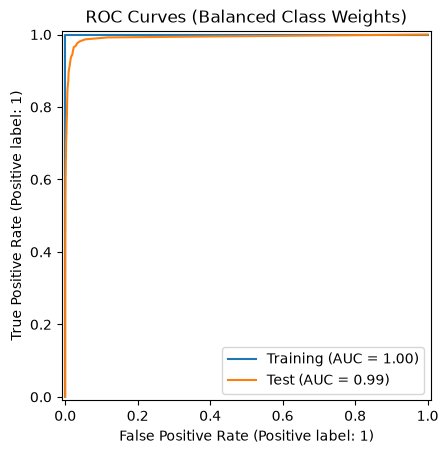

Out of Bag error: 0.007633333333333381
Test error: 0.01100000000000001
Out of Bag error - test error: -0.003366666666666629


In [9]:
rf_balanced = RandomForestClassifier(class_weight="balanced_subsample", oob_score=True)
rf_balanced.fit(X_train, y_train)

fig, ax = plt.subplots()

for name, X, y in [("Training", X_train, y_train), ("Test", X_test, y_test)]:
    pred = rf_balanced.predict(X)
    prob = rf_balanced.predict_proba(X)[:, 1]

    print(name)
    print("Confusion matrix:\n", confusion_matrix(y, pred))
    print("Misclassification rate:", (pred != y).mean())
    print("AUC:", roc_auc_score(y, prob))

    RocCurveDisplay.from_predictions(y, prob, name=name, ax=ax)

plt.title("ROC Curves (Balanced Class Weights)")
plt.show()

oob_error_balanced = 1 - rf_balanced.oob_score_
test_error_balanced = 1 - rf_balanced.score(X_test, y_test)

print("Out of Bag error:", oob_error_balanced)
print("Test error:", test_error_balanced)
print("Out of Bag error - test error:", oob_error_balanced - test_error_balanced)

Comparing result in 1(c) and 1(d):
Both models achieved 0% training error and a training AUC of 1.00. With class weighting, test misclassification increased from 0.74% to 1.10%, and test AUC decreased from 0.9934 to 0.9919.

False positives decreased from 19 to 10, but false negatives increased from 99 to 166. Positive-class recall decreased from 73.6% to 55.73%.

OOB error increased from 0.60% to 0.76%. Both OOB estimates were below the corresponding test errors, with the unweighted estimate closer.

Therefore, the unweighted random forest performed better.

### (e) XGBoost and Model Trees

Best alpha: 0.01
CV error: 0.006816666666666693
Test error: 0.007249999999999979
CV error - test error: -0.0004333333333332856
Training
Confusion matrix:
 [[59000     0]
 [    1   999]]
AUC: 1.0
Test
Confusion matrix:
 [[15592    33]
 [   83   292]]
AUC: 0.9908637013333332


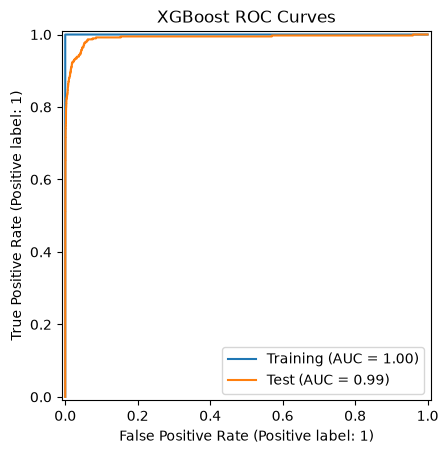

In [10]:
# use 5-fold cross validation method to estimate the error 
# use trees with logistic loss and l1 regularization
X_train_raw = pd.read_csv(
    "../data/aps_failure_training_set.csv", skiprows=20, na_values="na"
).drop(columns="class")

xgb = GridSearchCV(
    make_pipeline(SimpleImputer(), XGBClassifier(reg_lambda=0)),
    {"xgbclassifier__reg_alpha": [0, 0.01, 0.1, 1, 10]},
    cv=5
)
xgb.fit(X_train_raw, y_train)

cv_error = 1 - xgb.best_score_
test_error = 1 - xgb.score(X_test, y_test)

print("Best alpha:", xgb.best_params_["xgbclassifier__reg_alpha"])
print("CV error:", cv_error)
print("Test error:", test_error)
print("CV error - test error:", cv_error - test_error)

fig, ax = plt.subplots()

for name, X, y in [("Training", X_train_raw, y_train), ("Test", X_test, y_test)]:
    pred = xgb.predict(X)
    prob = xgb.predict_proba(X)[:, 1]

    print(name)
    print("Confusion matrix:\n", confusion_matrix(y, pred))
    print("AUC:", roc_auc_score(y, prob))

    RocCurveDisplay.from_predictions(y, prob, name=name, ax=ax)

plt.title("XGBoost ROC Curves")
plt.show()

### (f) Use SMOTE to pre-process your data

Best alpha: 0.1
CV error: 0.006266666666666643
Test error: 0.03818750000000004
CV error - test error: -0.0319208333333334
Training
Confusion matrix:
 [[59000     0]
 [    1   999]]
AUC: 0.9999999152542374
Test
Confusion matrix:
 [[15061   564]
 [   47   328]]
AUC: 0.9851941546666667


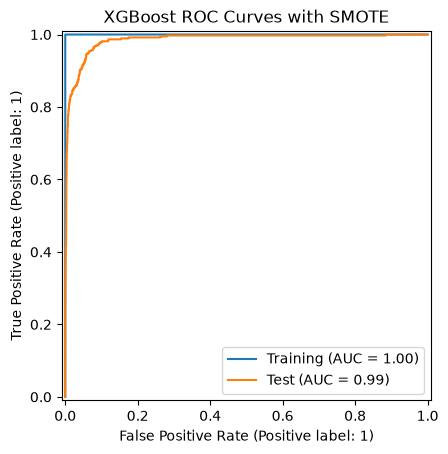

Test error without SMOTE: 0.007249999999999979
Test error with SMOTE: 0.03818750000000004


In [11]:
xgb_smote = GridSearchCV(
    make_pipeline(
        SimpleImputer(),
        StandardScaler(),
        SMOTE(),
        XGBClassifier(reg_lambda=0)
    ),
    {"xgbclassifier__reg_alpha": [0, 0.01, 0.1, 1, 10]},
    cv=5
)
xgb_smote.fit(X_train_raw, y_train)

cv_error_smote = 1 - xgb_smote.best_score_
test_error_smote = 1 - xgb_smote.score(X_test, y_test)

print("Best alpha:", xgb_smote.best_params_["xgbclassifier__reg_alpha"])
print("CV error:", cv_error_smote)
print("Test error:", test_error_smote)
print("CV error - test error:", cv_error_smote - test_error_smote)

fig, ax = plt.subplots()

for name, X, y in [("Training", X_train_raw, y_train), ("Test", X_test, y_test)]:
    pred = xgb_smote.predict(X)
    prob = xgb_smote.predict_proba(X)[:, 1]

    print(name)
    print("Confusion matrix:\n", confusion_matrix(y, pred))
    print("AUC:", roc_auc_score(y, prob))

    RocCurveDisplay.from_predictions(y, prob, name=name, ax=ax)

plt.title("XGBoost ROC Curves with SMOTE")
plt.show()

print("Test error without SMOTE:", 1 - xgb.score(X_test, y_test))
print("Test error with SMOTE:", test_error_smote)

With SMOTE, CV error decreased from 0.68% to 0.62%, but test error increased from 0.73% to 3.82%. Test AUC decreased from 0.99 to 0.98.

False negatives decreased from 83 to 47, improving positive-class recall from 77.87% to 87.47%. However, false positives increased from 33 to 564.

Therefore, SMOTE detected more failures but produced many more false alarms. The uncompensated model had lower test error and higher AUC. The SMOTE CV estimate also underestimated its test error.

## 2. ISLR 6.6.3

At $s=0$, all slope coefficients are zero. Increasing $s$ relaxes the lasso constraint $\sum_{j=1}^{p}|\beta_j|\leq s$, making the model more flexible.

**(a) Training RSS: iv. Steadily decrease.**

Increasing $s$ allows more coefficient values while keeping the previous solution available. Therefore, the minimum training RSS cannot increase. It decreases until the least squares solution is allowed, then remains constant.

**(b) Test RSS: ii. Decrease initially, and then eventually start increasing in a U shape.**

Initially, greater flexibility reduces underfitting and squared bias, lowering test RSS. Eventually, the increase in variance outweighs the decrease in squared bias, raising test RSS. 

**(c) Variance: iii. Steadily increase.**

As $s$ increases, less shrinkage makes the fitted model more sensitive to changes in the training data. Therefore, variance generally increases.

**(d) Squared bias: iv. Steadily decrease.**

As $s$ increases, the coefficients are less restricted, allowing the model to better approximate the true relationship. Therefore, squared bias generally decreases.

**(e) Irreducible error: v. Remain constant.**

The irreducible error, $\operatorname{Var}(\epsilon)$, depends on the noise in the data. It does not depend on $s$, so it remains constant.


## 3. ISLR 6.6.5

Since $\hat{\beta}_0=0$, $x_{12}=x_{11}$, $x_{22}=x_{21}=-x_{11}$, and $y_2=-y_1$, the RSS becomes
$$
\begin{aligned}
RSS
&=(y_1-\beta_1x_{11}-\beta_2x_{12})^2
 +(y_2-\beta_1x_{21}-\beta_2x_{22})^2\\
&=2[y_1-x_{11}(\beta_1+\beta_2)]^2.
\end{aligned}
$$

**(a)**

The ridge regression optimization problem is
$$
\min_{\beta_1,\beta_2}
\left\{
2[y_1-x_{11}(\beta_1+\beta_2)]^2
+\lambda(\beta_1^2+\beta_2^2)
\right\}.
$$

**(b)**

For $\lambda>0$, setting the two partial derivatives equal to zero gives
$$
-4x_{11}[y_1-x_{11}(\hat{\beta}_1+\hat{\beta}_2)]
+2\lambda\hat{\beta}_1=0,
$$
$$
-4x_{11}[y_1-x_{11}(\hat{\beta}_1+\hat{\beta}_2)]
+2\lambda\hat{\beta}_2=0.
$$

Subtracting these equations,
$$
2\lambda(\hat{\beta}_1-\hat{\beta}_2)=0.
$$

Therefore, $\boxed{\hat{\beta}_1=\hat{\beta}_2}$.

**(c)**

The lasso optimization problem is
$$
\min_{\beta_1,\beta_2}
\left\{
2[y_1-x_{11}(\beta_1+\beta_2)]^2
+\lambda(|\beta_1|+|\beta_2|)
\right\}.
$$

**(d)**

Let $b=\beta_1+\beta_2$. The RSS depends only on $b$. By the triangle inequality,
$$
|\beta_1|+|\beta_2|\geq|\beta_1+\beta_2|=|b|,
$$
with equality when the coefficients have the same sign or one is zero.

Thus, the optimal sum $\hat b$ minimizes
$$
2(y_1-x_{11}b)^2+\lambda|b|.
$$

Every pair
$$
\boxed{
\hat{\beta}_1=t\hat b,\qquad
\hat{\beta}_2=(1-t)\hat b,\qquad 0\leq t\leq1
}
$$
has the same RSS and the same penalty $\lambda|\hat b|$.

Therefore, when $\hat b\neq0$, there are infinitely many lasso solutions, including $(\hat b,0)$, $(0,\hat b)$, and $(\hat b/2,\hat b/2)$.

If $\hat b=0$ and $\lambda>0$, the unique solution is $(0,0)$. Thus, nonuniqueness applies when the optimal sum is nonzero.

## 4. ISLR 8.4.5

**Majority vote:**

Each tree predicts Red if its estimated $P(\text{Red}\mid X)>0.5$, and Green otherwise. Among the $B=10$ trees, 6 predict Red and 4 predict Green.

Therefore, the final classification is Red.

**Average probability:**

The average estimated probability of Red is
$$
\frac{0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75}{10}
=\frac{4.5}{10}=0.45.
$$

Since $0.45<0.5$, the final classification is Green.

## 5. ISLR 9.7.3

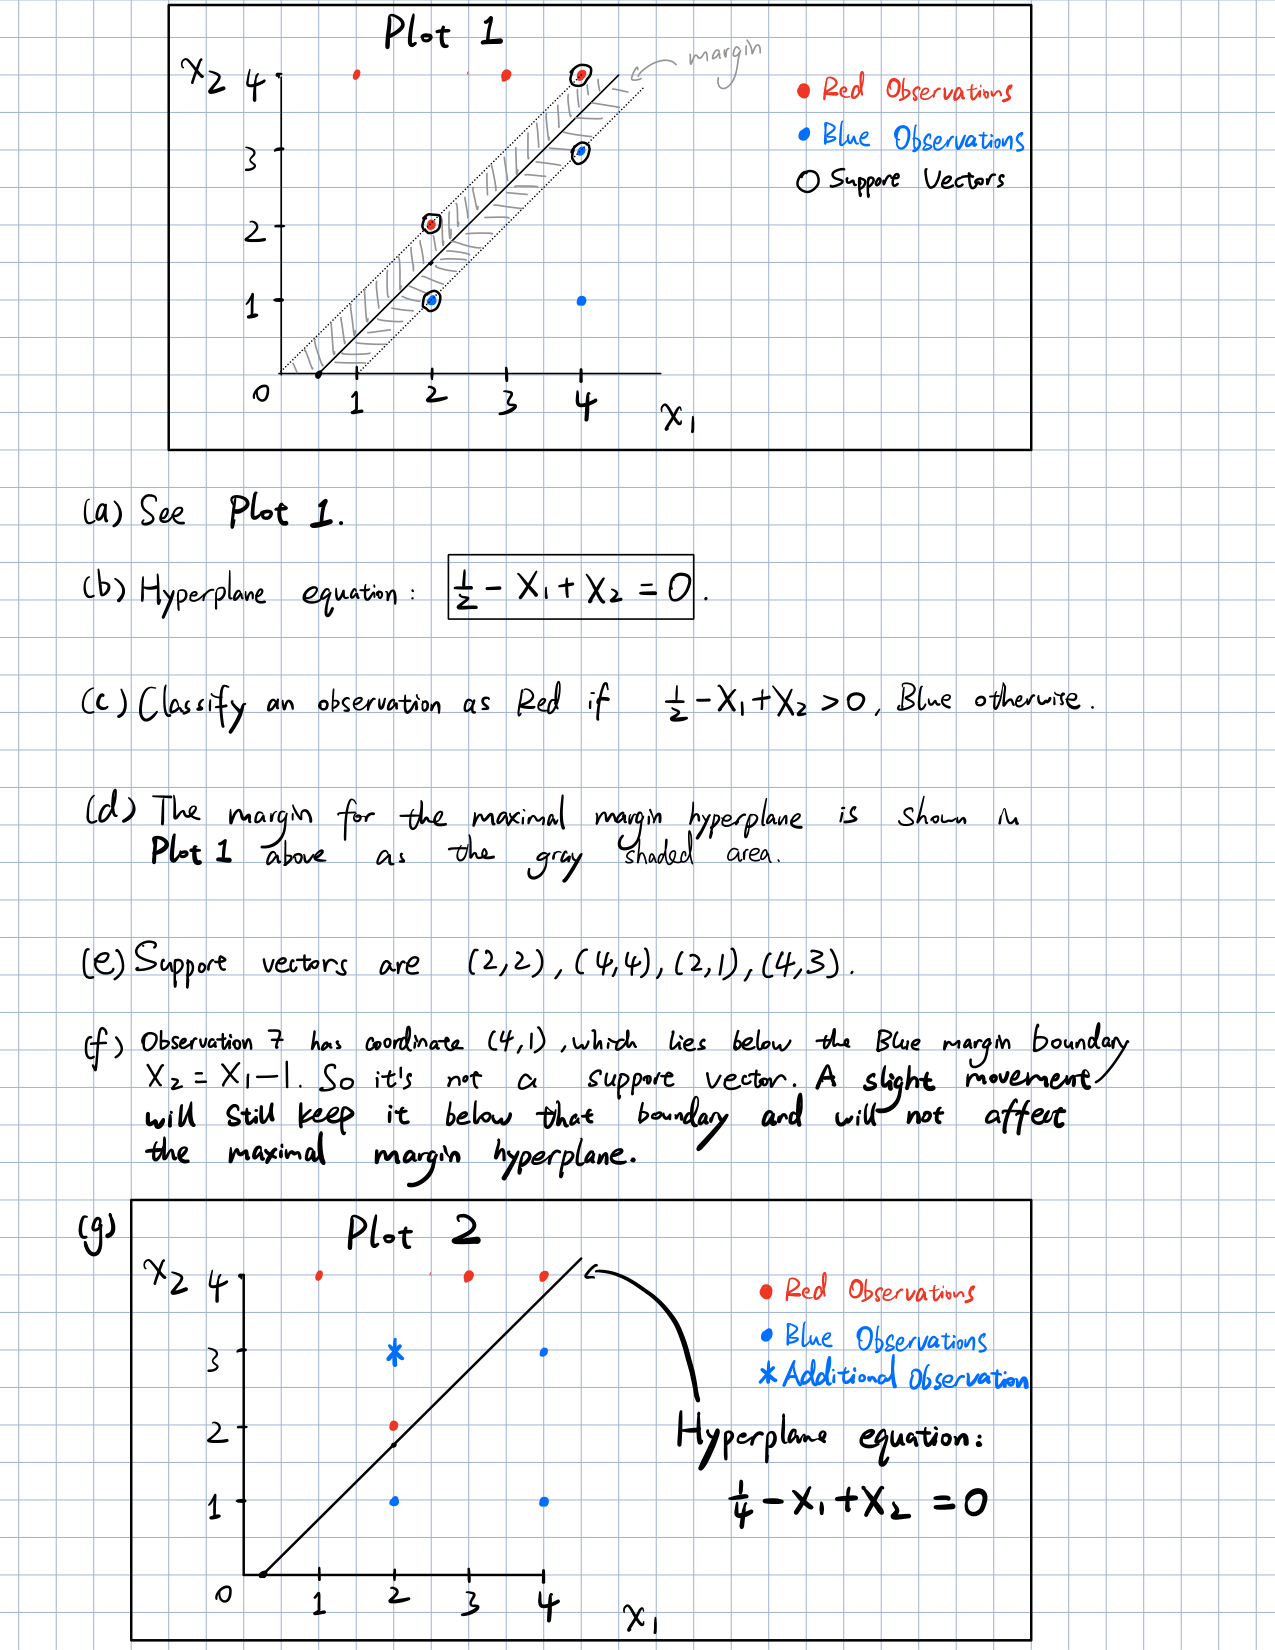

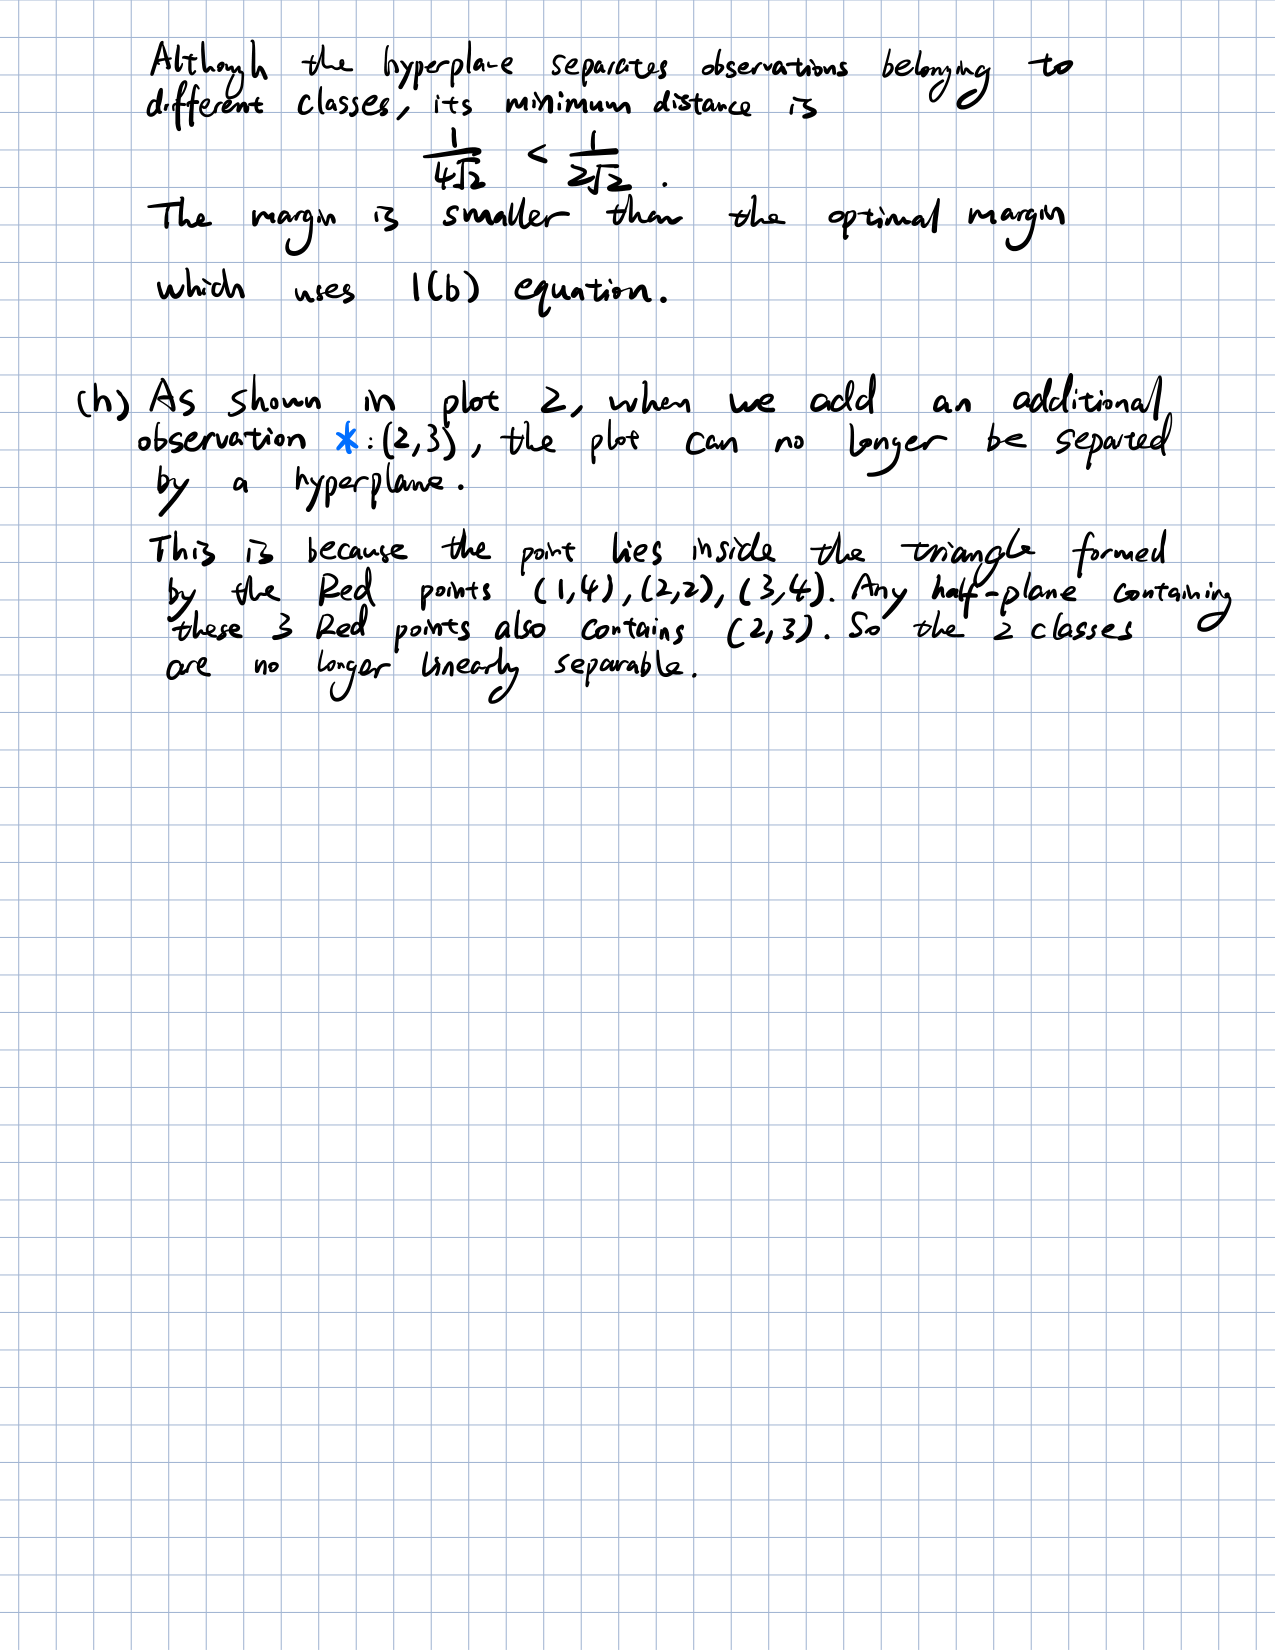

In [12]:
with pymupdf.open("../HW6 ISLR 9.7.3.pdf") as pdf:
    for page in pdf:
        display(Image(data=page.get_pixmap(dpi=150).tobytes("png")))

# AI-Use Log

Tool: Claude (Anthropic), model Claude Opus 5.5.

| ID | Exact prompt | Assignment part | How I used the response |
|---|---|---|---|
| P1 | "what are the common technique to deal with missing values in datasets? Give me the sources as well" | Question 1(b)(i) | I used the response to learn the common options (deletion, mean/median/mode imputation, KNN and iterative imputation, multiple imputation) and the MCAR/MAR/MNAR distinction, and used the scikit-learn imputation guide as my reference. |
| P2 | "what's the general code to train a random forest using sklearn. How to calculate confusion matrix, ROC, AUC, misclassification error for train and test set using sklearn. Explain Out of Bag errror" | Question 1(c) | I used the general template to fit a `RandomForestClassifier`, compute the confusion matrix, ROC curve, AUC, and misclassification error on the training and test sets, and to understand how the OOB error is estimated from `oob_score_`. |
| P3 | "how to deal with class imbalance in random forest, give me the source" | Question 1(d) | I learned the main approaches (class weighting, balanced random forest, resampling, threshold tuning, imbalance-aware metrics) and used the scikit-learn `RandomForestClassifier` docs as my reference. |
| P4 | "what's the sample code to do class weighting in random forest" | Question 1(d) | I used the sample code to understand how to set `class_weight` (`"balanced"` vs. `"balanced_subsample"`) when refitting the random forest. |
| P5 | "what is the sample code to use SMOTE (Synthetic Minority Over-sampling Technique) to pre-process data to compensate for class imbalance. Explain." | Question 1(f) | I learned how SMOTE generates synthetic minority samples and how to apply it only to the training data with an `imblearn` pipeline, so the test set is not resampled. |